# Customer churn prediction with explainabality 
predict cusgtomer churn, and also analyse the attributes that have major impact on the decision by model 

## The dataset is from IBM analytics, also available on Kaggle
https://www.kaggle.com/datasets/blastchar/telco-customer-churn/data


## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix 
import os
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import joblib

## Load the dataset 

In [2]:
# dataset path 
data_path = os.path.join("data", "dataset.csv")
# load dataset
data = pd.read_csv(data_path)
# display first few rows
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Start building the Pipeline 

1️⃣ Split data and define preprocessor (ColumnTransformer) <br>
2️⃣ Define model <br>
3️⃣ Create Pipeline([('preprocessor', ...), ('classifier', ...)]) <br>
4️⃣ Run GridSearchCV on the Pipeline <br>
5️⃣ Save search.best_estimator_ (the entire fitted pipeline) <br>
6️⃣ Deploy that pipeline <br>

In [3]:

# drop customerID column
data = data.drop('customerID', axis=1)
# handle missing values in TotalCharges
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce')
# drop rows with missing TotalCharges
data = data.dropna(subset=['TotalCharges'])
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7032 non-null   object 
 1   SeniorCitizen     7032 non-null   int64  
 2   Partner           7032 non-null   object 
 3   Dependents        7032 non-null   object 
 4   tenure            7032 non-null   int64  
 5   PhoneService      7032 non-null   object 
 6   MultipleLines     7032 non-null   object 
 7   InternetService   7032 non-null   object 
 8   OnlineSecurity    7032 non-null   object 
 9   OnlineBackup      7032 non-null   object 
 10  DeviceProtection  7032 non-null   object 
 11  TechSupport       7032 non-null   object 
 12  StreamingTV       7032 non-null   object 
 13  StreamingMovies   7032 non-null   object 
 14  Contract          7032 non-null   object 
 15  PaperlessBilling  7032 non-null   object 
 16  PaymentMethod     7032 non-null   object 
 17  

In [4]:
# get X and y from the data based on 'Churn' column
X = data.drop('Churn', axis=1)
y = data['Churn']   


# train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
# display shapes
print(f"Shapes of train and test sets:")
print(f"X train: {X_train.shape}")
print(f"X test: {X_test.shape}")
print(f"y train: {y_train.shape}")
print(f"y test: {y_test.shape}")
X.info()

# identify categorical and numerical columns
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X.select_dtypes(include=['float64', 'int64']).columns.tolist()
print(f"Categorical columns: {categorical_cols}")
print(f"Numerical columns: {numerical_cols}")



Shapes of train and test sets:
X train: (5625, 19)
X test: (1407, 19)
y train: (5625,)
y test: (1407,)
<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7032 non-null   object 
 1   SeniorCitizen     7032 non-null   int64  
 2   Partner           7032 non-null   object 
 3   Dependents        7032 non-null   object 
 4   tenure            7032 non-null   int64  
 5   PhoneService      7032 non-null   object 
 6   MultipleLines     7032 non-null   object 
 7   InternetService   7032 non-null   object 
 8   OnlineSecurity    7032 non-null   object 
 9   OnlineBackup      7032 non-null   object 
 10  DeviceProtection  7032 non-null   object 
 11  TechSupport       7032 non-null   object 
 12  StreamingTV       7032 non-null   object 
 13  StreamingMovies   7032 non-null   object 
 14  Contract          7032 non-null   obje

In [7]:
print(y_test) 

974      No
619      No
4289     No
3721    Yes
4533     No
       ... 
4829     No
5176     No
2750     No
4432     No
2091     No
Name: Churn, Length: 1407, dtype: object


# pipeline steps
1️⃣ Split data and define preprocessor (ColumnTransformer) <br>
2️⃣ Define model <br>
3️⃣ Create Pipeline([('preprocessor', ...), ('classifier', ...)]) <br>
4️⃣ Run GridSearchCV on the Pipeline <br>
5️⃣ Save search.best_estimator_ (the entire fitted pipeline) <br>
6️⃣ Deploy that pipeline <br>

In [ ]:
# define prepreocessor
numeric_transformer = StandardScaler()
# for categorical we will use both OneHotEncoder and ordinal encoding, we will use them in different models
onehot = OneHotEncoder(handle_unknown="ignore")
ordinal = OrdinalEncoder()

# categoriacal oneHOt is placeholder here. It will be replaced/swapped in GridSearchCV
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('cat', onehot, categorical_cols)
                ],
        remainder='passthrough',
        verbose_feature_names_out=False
    )

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

# define parameter grid for GridSearchCV
param_grid = [
    
    {
        "preprocessor__cat": [ordinal],
        "classifier": [RandomForestClassifier()],
        "classifier__n_estimators": [25, 50, 100, 150],
        "classifier__max_depth": [3, 5, None],
        "classifier__criterion": ["gini", "entropy"],
    },
    {
        "preprocessor__cat": [onehot],
        "classifier": [SVC()],
        "classifier__C": [0.1, 1, 10],
        "classifier__kernel": ["linear", "rbf"],
    },
    {
        "preprocessor__cat": [onehot],
        "classifier": [LogisticRegression(max_iter=1000)],
        "classifier__C": [0.1, 1, 10],
        "classifier__penalty": ["l2"],
    },
]

In [27]:
grid_search = GridSearchCV(pipeline, param_grid, cv=5, n_jobs=-1, scoring="accuracy")
grid_search.fit(X_train, y_train)

print("Grid Search completed.")


print(f"Best parameters: {grid_search.best_params_}")
print(f"Best cross-validation score: {grid_search.best_score_}")
best_model = grid_search.best_estimator_




Grid Search completed.
Best parameters: {'classifier': SVC(), 'classifier__C': 1, 'classifier__kernel': 'rbf', 'preprocessor__cat': OneHotEncoder(handle_unknown='ignore')}
Best cross-validation score: 0.8005333333333333


In [28]:
best_model

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


In [29]:

y_pred = best_model.predict(X_test)
print("Classification Report:")
print(classification_report(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

          No       0.83      0.90      0.86      1033
         Yes       0.64      0.49      0.56       374

    accuracy                           0.79      1407
   macro avg       0.74      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407

Confusion Matrix:
[[929 104]
 [189 185]]


## create pipeline for RF, which will be used for fearure importance 

In [ ]:
# build rf pipeline for feature importance 
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])  

# build grid search for rf pipeline
rf_param_grid = {
    "preprocessor__cat": [ordinal],
    "classifier__n_estimators": [50,100,150],
    "classifier__max_depth": [3,5,10,15,None],
    "classifier__criterion": ["gini", "entropy"],
}

# run grid search
rf_grid_search = GridSearchCV(estimator= rf_pipeline, param_grid= rf_param_grid, cv=5, n_jobs=-1, verbose=2, scoring="accuracy", return_train_score=True)
rf_grid_search.fit(X_train, y_train)

print("Random Forest Grid Search completed.")
print(f"Best parameters for RF: {rf_grid_search.best_params_}")
print(f"Best cross-validation score for RF: {rf_grid_search.best_score_}")
rf_best_model = rf_grid_search.best_estimator_



Fitting 5 folds for each of 30 candidates, totalling 150 fits


/Users/atif/.pyenv/versions/3.12.2/lib/python3.12/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/Users/atif/.pyenv/versions/3.12.2/lib/python3.12/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/Users/atif/.pyenv/versions/3.12.2/lib/python3.12/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from usi

[CV] END classifier__criterion=gini, classifier__max_depth=3, classifier__n_estimators=50, preprocessor__cat=OrdinalEncoder(); total time=   0.4s
[CV] END classifier__criterion=gini, classifier__max_depth=3, classifier__n_estimators=50, preprocessor__cat=OrdinalEncoder(); total time=   0.4s
[CV] END classifier__criterion=gini, classifier__max_depth=3, classifier__n_estimators=50, preprocessor__cat=OrdinalEncoder(); total time=   0.4s
[CV] END classifier__criterion=gini, classifier__max_depth=3, classifier__n_estimators=50, preprocessor__cat=OrdinalEncoder(); total time=   0.4s
[CV] END classifier__criterion=gini, classifier__max_depth=3, classifier__n_estimators=50, preprocessor__cat=OrdinalEncoder(); total time=   0.4s
[CV] END classifier__criterion=gini, classifier__max_depth=3, classifier__n_estimators=100, preprocessor__cat=OrdinalEncoder(); total time=   0.8s
[CV] END classifier__criterion=gini, classifier__max_depth=3, classifier__n_estimators=100, preprocessor__cat=OrdinalEncode

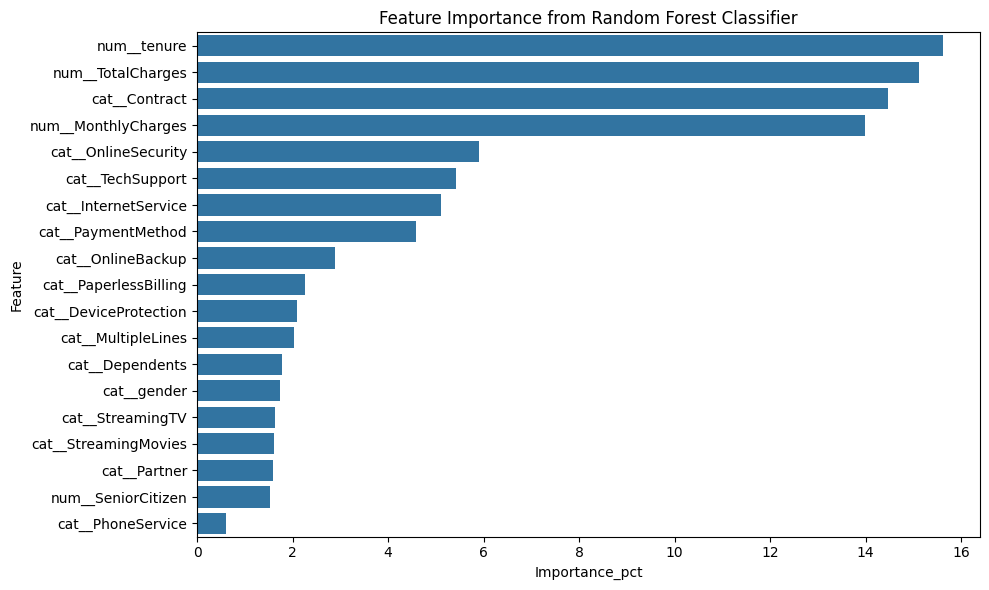

In [38]:
# get the featues from the bset model for feature importance

# feature importance
rf_classifier = rf_best_model.named_steps['classifier']
feature_names = rf_best_model.named_steps['preprocessor'].get_feature_names_out()
importances = rf_classifier.feature_importances_
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_importance_df['Importance_pct'] = feature_importance_df['Importance'] / feature_importance_df['Importance'].sum() * 100

feature_importance_df = feature_importance_df.sort_values(by='Importance_pct', ascending=False)

# plot feature importance
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance_pct', y='Feature', data=feature_importance_df)
plt.title('Feature Importance from Random Forest Classifier')
plt.tight_layout()
plt.show()


In [39]:
feature_importance_df.head(10)

,Feature,Importance,Importance_pct
1,num__tenure,0.156169,15.616857
3,num__TotalCharges,0.151295,15.129547
16,cat__Contract,0.144712,14.471211
2,num__MonthlyCharges,0.139806,13.980620
10,cat__OnlineSecurity,0.059040,5.904030
13,cat__TechSupport,0.054159,5.415925
9,cat__InternetService,0.051046,5.104576
18,cat__PaymentMethod,0.045778,4.577765
11,cat__OnlineBackup,0.028995,2.899483
17,cat__PaperlessBilling,0.022704,2.270437


In [40]:
# save the best model
model_path = os.path.join("models", "best_churn_model.pkl")
feature_importance_path = os.path.join("models", "feature_importance.csv")

# create models directory if it doesn't exist
os.makedirs("models", exist_ok=True)
joblib.dump(best_model, model_path)
feature_importance_df.to_csv(feature_importance_path, index=False)

print(f"Best model saved to {model_path}")  

Best model saved to models/best_churn_model.pkl


In [12]:
# load saved model for testing
model_path = os.path.join("models", "best_churn_model.pkl")
loaded_model = joblib.load(model_path)
y_pred = loaded_model.predict(X_test)
print(classification_report(y_test, y_pred))
# print accuracy
from sklearn.metrics import accuracy_score
print(f"Accuracy of loaded model: {accuracy_score(y_test, y_pred)}")

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1033
         Yes       0.65      0.57      0.61       374

    accuracy                           0.81      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.81      0.80      1407

Accuracy of loaded model: 0.8052594171997157


In [30]:
clf = loaded_model.named_steps['classifier']
# get feature importances if the classifier has the attribute
if hasattr(clf, 'feature_importances_'):
    importances = clf.feature_importances_
#    print("Feature Importances:")
#    print(importances)

preprocessor = loaded_model.named_steps['preprocessor']
feature_names = preprocessor.get_feature_names_out()
#print(f"Feature Names: {feature_names}")

# create a dataframe for feature importances
if hasattr(clf, 'feature_importances_'):
    feature_importances = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importances
    })
    feature_importances = feature_importances.sort_values(by='Importance', ascending=False)
    print(feature_importances)
    plt.figure(figsize=(10,6))
    sns.barplot(x='Importance', y='Feature', data=feature_importances)
    plt.title('Feature Importance')
    plt.show()


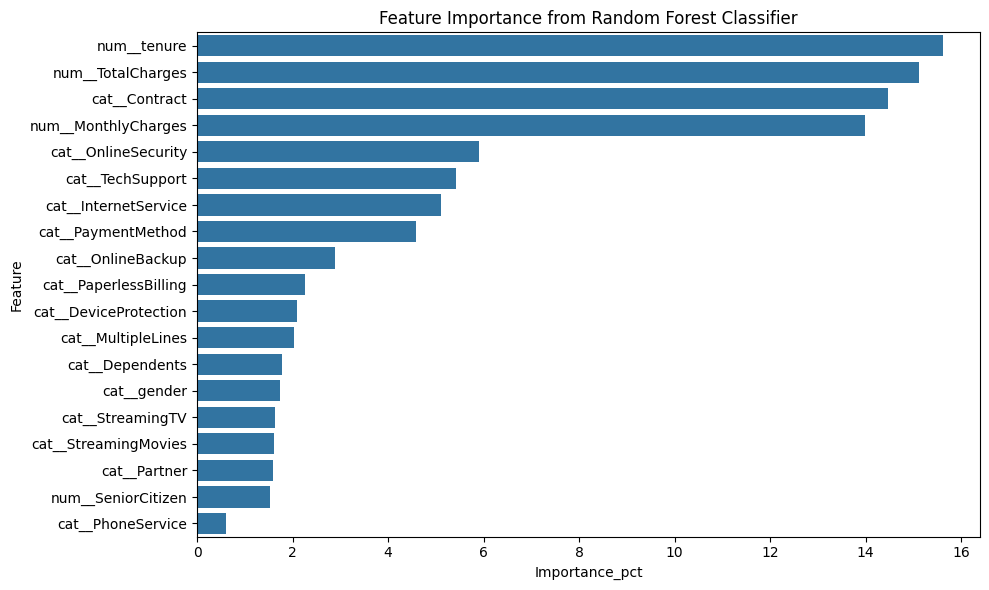

In [41]:
# load csv file for feature importance
feature_importance_path = os.path.join("models", "feature_importance.csv")
feature_importance_df = pd.read_csv(feature_importance_path)
# plot feature importance
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance_pct', y='Feature', data=feature_importance_df)
plt.title('Feature Importance from Random Forest Classifier')
plt.tight_layout()
plt.show()  

In [11]:
# save x_test to csv for later use
x_test_path = os.path.join("models", "x_test.csv")
X_test.to_csv(x_test_path, index=False)
# save y_test and y_pred to csv for later use
y_test_path = os.path.join("models", "y_test.csv")
y_pred_path = os.path.join("models", "y_pred.csv")
y_test.to_csv(y_test_path, index=False)
